# Task 4 Semi-supervised learning for unlabeled data

## Imports

In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import missingno as msno
import seaborn as sns
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_predict
from xgboost import XGBRegressor
from catboost import CatBoostRegressor, Pool
from sklearn.manifold import Isomap
from sklearn.decomposition import PCA
from sklearn.base import BaseEstimator

## Auxiliary functions

In [79]:
def cMSE(y, y_hat, c):
    err = y-y_hat
    err = (1-c)*err**2 + c*np.maximum(0,err)**2
    return np.sum(err)/err.shape[0]
    
def plot_y_yhat(y_test, y_pred, plot_title="plot"):
    # Only one target variable: SurvivalTime
    label = 'SurvivalTime'
    MAX = 500

    # Select indices for plotting
    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test), MAX, replace=False)
    else:
        idx = np.arange(len(y_test))

    # Plot True vs Predicted for SurvivalTime
    plt.figure(figsize=(6, 6))
    x0 = np.min(y_test[idx])
    x1 = np.max(y_test[idx])
    plt.scatter(y_test[idx], y_pred[idx], alpha=0.7)
    plt.xlabel(f'True {label}')
    plt.ylabel(f'Predicted {label}')
    plt.plot([x0, x1], [x0, x1], color='red')
    plt.title(f'True vs Predicted {label}')
    plt.axis('square')
    plt.savefig(plot_title + '.pdf')
    plt.show()
    
def save_predictions(predictions, path):
    # Create a DataFrame with the 'id' column and the predictions
    df = pd.DataFrame({
        'id': range(len(predictions)),
        '0': predictions
    })
    
    # Save the DataFrame to a CSV file
    df.to_csv(path, index=False)
    
def model_metrics(y_true, y_pred):
    error = y_true - y_pred
    metrics = {
        'Metric': ['Max Error', 'Min Error', 'Mean Error', 'Std of Error'],
        'Value': [
            np.max(np.abs(error)),
            np.min(np.abs(error)),
            np.mean(np.abs(error)),
            np.std(error)
        ]
    }
    return pd.DataFrame(metrics)


def evaluate_model(X, y, c, model, show_cmse=True, show_metrics=False, show_plot=False):
    # Train-test split
    X_train, X_test, y_train, y_test, c_train, c_test = train_test_split(X, y, c, test_size=0.2, random_state=30)
    
    # Cross validation
    y_pred_cv = cross_val_predict(model, X_train, y_train, cv=10)
    cMSE_cv = cMSE(y_train, y_pred_cv, c_train)
    
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    cMSE_test = cMSE(y_test, y_pred, c_test)
    
    if show_cmse:
        print(f"CV cMSE: {cMSE_cv}")
        print(f"Test cMSE: {cMSE_test}")
    
    if show_metrics:
        metrics = model_metrics(y_test, y_pred)
        print(metrics.T.to_string(index=False, header=False))
    
    if show_plot:
        plot_y_yhat(y_test, y_pred, plot_title="y_yhat_plot")
    
    return model, cMSE_cv

## Data processing

In [80]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)

labeled_df = df.dropna(subset=['SurvivalTime'])
unlabeled_df = df[df['SurvivalTime'].isna()]

X_labeled = labeled_df.drop(columns=['SurvivalTime', 'Censored'])
y_labeled = labeled_df['SurvivalTime']
c_labeled = labeled_df['Censored']

X_unlabeled = unlabeled_df.drop(columns=['SurvivalTime', 'Censored'])
c_unlabeled = unlabeled_df['Censored']

X = pd.concat([X_labeled, X_unlabeled])
c = pd.concat([c_labeled, c_unlabeled])

# Task 4.1: Imputation with labeled and unlabeled data

### Fit with the best imputation methods from Task 3.1

#### Best imputer from task 3.1 was KNN imputer with K=19

In [81]:
knn_imputer = KNNImputer(n_neighbors=19)
X_imp = pd.DataFrame(knn_imputer.fit_transform(X), columns=X.columns)
X_labeled_imp = X_imp.iloc[:len(labeled_df)]

#### Use the imputed data with labels to train a Linear Regression model

In [82]:
linear_reg = make_pipeline(StandardScaler(), LinearRegression())
lr_imp_model, lr_imp_csme = evaluate_model(np.array(X_labeled_imp), np.array(
    y_labeled), np.array(c_labeled), model=linear_reg)

CV cMSE: 2.606016778008581
Test cMSE: 2.418972175074191


### Training an Isomap lower dimensional representation of the data

#### Required wrapper code

In [83]:
class FrozenTransformer(BaseEstimator):
    def __init__(self, fitted_transformer):
        self.fitted_transformer = fitted_transformer

    def __getattr__(self, name):
        # `fitted_transformer`'s attributes are now accessible
        return getattr(self.fitted_transformer, name)

    def __sklearn_clone__(self):
        return self

    def fit(self, X, y=None):
        # Fitting does not change the state of the estimator
        return self

    def transform(self, X, y=None):
        # transform only transforms the data
        return self.fitted_transformer.transform(X)

    def fit_transform(self, X, y=None):
        # fit_transform only transforms the data
        return self.fitted_transformer.transform(X)

#### Standardize the features

In [84]:
scaler = StandardScaler()
X_imp_scaled = scaler.fit_transform(X_imp)

#### Try out FrozenTransformer

In [85]:
iso = Isomap(n_components=2)
iso.fit(X_imp_scaled)

ft_lr_model = make_pipeline(
    knn_imputer, 
    scaler, 
    FrozenTransformer(iso), 
    LinearRegression())

ft_lr_imp_model, ft_lr_imp_csme = evaluate_model(np.array(
    X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_lr_model)

CV cMSE: 3.313122893795961
Test cMSE: 3.0789281225763125


#### Without PCA, find out best n_components for Isomap

##### Plot performance of different number of components on Isomap

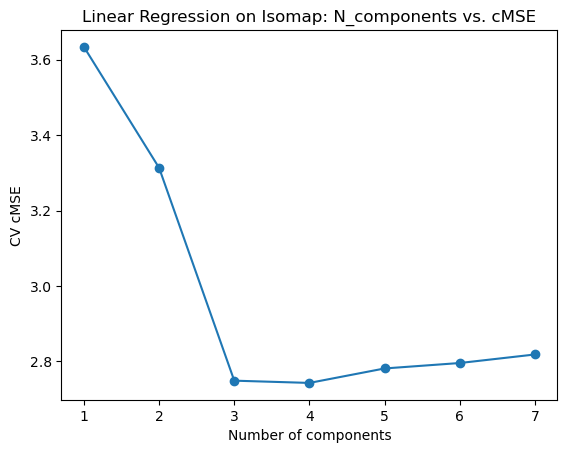

In [86]:
n_values = range(1, 8)
ft_lr_scores = []

for n in n_values:
    iso = Isomap(n_components=n)
    iso.fit(X_imp_scaled)
    
    ft_lr_model = make_pipeline(
    knn_imputer, 
    scaler, 
    FrozenTransformer(iso), 
    LinearRegression())
    
    _, score = evaluate_model(np.array(
    X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_lr_model, show_cmse=False)
    
    ft_lr_scores.append(score)
    
plt.plot(n_values, ft_lr_scores, marker='o')
plt.xlabel("Number of components")
plt.ylabel("CV cMSE")
plt.title("Linear Regression on Isomap: N_components vs. cMSE")
plt.show()

##### Best number of components is 4

In [88]:
iso = Isomap(n_components=4)
iso.fit(X_imp_scaled)

ft_lr_model = make_pipeline(
    knn_imputer, 
    scaler, 
    # pca,
    FrozenTransformer(iso), 
    LinearRegression())

ft_lr_imp_model, ft_lr_imp_csme = evaluate_model(np.array(
    X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_lr_model)

CV cMSE: 2.743067094031062
Test cMSE: 2.790788187401173


#### For best Isomap (4 components), find out best n_components for PCA 

PCA does NOT help in this case

##### Plot performance of different component numbers on PCA

c:\Users\rasvi\anaconda3\envs\ml\Lib\site-packages\sklearn\manifold\_isomap.py:359: UserWarning: The number of connected components of the neighbors graph is 6 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
c:\Users\rasvi\anaconda3\envs\ml\Lib\site-packages\scipy\sparse\_index.py:108: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_intXint(row, col, x.flat[0])
c:\Users\rasvi\anaconda3\envs\ml\Lib\site-packages\scipy\sparse\_index.py:108: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_intXint(row, col, x.flat[0])
c:\Users\rasvi\anaconda3\envs\ml\Lib\site-packages\scipy\sparse\_index.py:108: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_intXint(row, col, x.flat

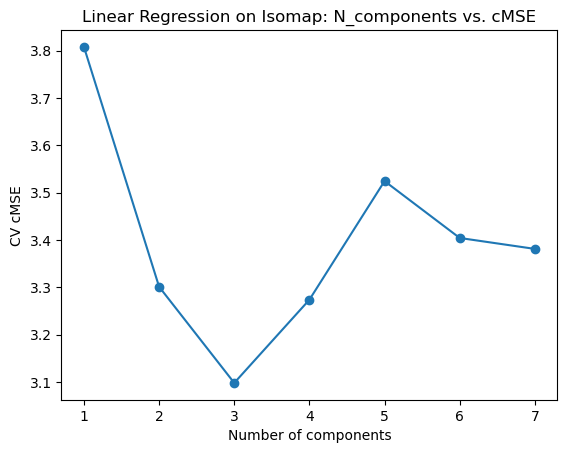

In [89]:
n_values = range(1, 8)
ft_lr_scores = []

for n in n_values:
    pca = PCA(n_components=n)
    X_pca = pca.fit_transform(X_imp_scaled)
    
    iso = Isomap(n_components=4)
    iso.fit(X_pca)
    
    ft_lr_model = make_pipeline(
    knn_imputer, 
    scaler,
    pca,
    FrozenTransformer(iso), 
    LinearRegression())
    
    _, score = evaluate_model(np.array(
    X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_lr_model, show_cmse=False)
    
    ft_lr_scores.append(score)
    
plt.plot(n_values, ft_lr_scores, marker='o')
plt.xlabel("Number of components")
plt.ylabel("CV cMSE")
plt.title("Linear Regression on Isomap: N_components vs. cMSE")
plt.show()

##### Best number of components is 3

In [90]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_imp_scaled)

iso = Isomap(n_components=4)
iso.fit(X_pca)

ft_lr_model = make_pipeline(
knn_imputer, 
scaler,
pca,
FrozenTransformer(iso), 
LinearRegression())

ft_lr_pca_model = make_pipeline(
    knn_imputer, 
    scaler, 
    pca,
    FrozenTransformer(iso), 
    LinearRegression())

_, _ = evaluate_model(np.array(
    X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_lr_model)

CV cMSE: 3.098207207441531
Test cMSE: 2.5444805696691994


## Task 4.2 Evaluation

### Try the best imputation strategies of Task 3.1, impute the data, run the best model of task 3.2 and compare with the baseline in the slides.

##### KNN imputer with K=19

In [91]:
knn_imputer = KNNImputer(n_neighbors=19)
X_imp = pd.DataFrame(knn_imputer.fit_transform(X), columns=X.columns)
X_labeled_imp = X_imp.iloc[:len(labeled_df)]

##### Train best model from task 3.2 (CatBoost with learning rate=0.01 and max_depth=1)

In [92]:
scaler = StandardScaler()
X_imp_scaled = scaler.fit_transform(X_imp)

iso = Isomap(n_components=6)
iso.fit(X_imp_scaled)

model = CatBoostRegressor(random_state=30, max_depth=1, learning_rate=0.01, silent=True)

ft_cat_model = make_pipeline(
    knn_imputer, 
    FrozenTransformer(iso), 
    model)

ft_cat_imp_model, ft_cat_imp_csme = evaluate_model(np.array(
    X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_cat_model)

CV cMSE: 3.7533233308471297
Test cMSE: 3.292334681883934


##### Find best value for n_components

CV cMSE: 3.7706396786344576
Test cMSE: 3.4399716556756563
CV cMSE: 3.7942936739909263
Test cMSE: 3.469139908694938
CV cMSE: 3.756038933560223
Test cMSE: 3.363139920462345
CV cMSE: 3.79055130077958
Test cMSE: 3.343869692397732
CV cMSE: 3.7826646647908078
Test cMSE: 3.3311221921728262
CV cMSE: 3.7533233308471297
Test cMSE: 3.292334681883934
CV cMSE: 3.6035637118334876
Test cMSE: 3.3119745829942473


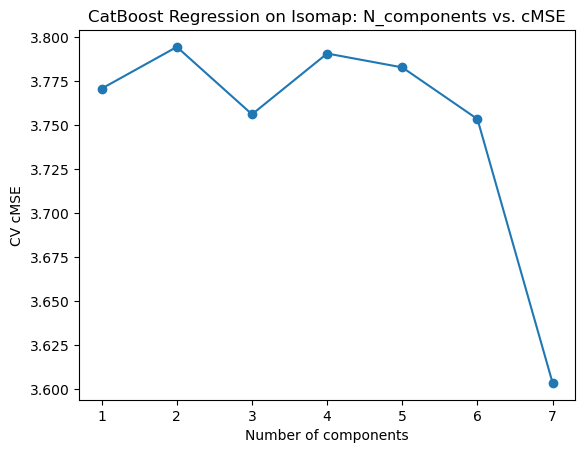

In [93]:
n_values = range(1, 8)
ft_cat_scores = []

for n in n_values:
    iso = Isomap(n_components=n)
    iso.fit(X_imp_scaled)

    model = CatBoostRegressor(random_state=30, max_depth=1, learning_rate=0.01, silent=True)

    ft_cat_model = make_pipeline(
        knn_imputer,
        FrozenTransformer(iso),
        model)

    _, score = evaluate_model(np.array(
        X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_cat_model, show_cmse=True)

    ft_cat_scores.append(score)

plt.plot(n_values, ft_cat_scores, marker='o')
plt.xlabel("Number of components")
plt.ylabel("CV cMSE")
plt.title("CatBoost Regression on Isomap: N_components vs. cMSE")
plt.show()